Total records: 150
Number of features: 4
Iris-setosa : 50
Iris-versicolor : 50
Iris-virginica : 50

Training records: 99
Testing records: 51
Epoch: 1 | Training Accuracy: 66.67 % | Test Accuracy: 72.55 %
Epoch: 2 | Training Accuracy: 87.88 % | Test Accuracy: 90.2 %
Epoch: 3 | Training Accuracy: 87.88 % | Test Accuracy: 90.2 %
Epoch: 4 | Training Accuracy: 88.89 % | Test Accuracy: 88.24 %
Epoch: 5 | Training Accuracy: 88.89 % | Test Accuracy: 88.24 %
Epoch: 6 | Training Accuracy: 87.88 % | Test Accuracy: 92.16 %
Epoch: 7 | Training Accuracy: 87.88 % | Test Accuracy: 92.16 %
Epoch: 8 | Training Accuracy: 88.89 % | Test Accuracy: 92.16 %
Epoch: 9 | Training Accuracy: 88.89 % | Test Accuracy: 92.16 %
Epoch: 10 | Training Accuracy: 88.89 % | Test Accuracy: 92.16 %
Epoch: 11 | Training Accuracy: 88.89 % | Test Accuracy: 90.2 %
Epoch: 12 | Training Accuracy: 88.89 % | Test Accuracy: 90.2 %
Epoch: 13 | Training Accuracy: 88.89 % | Test Accuracy: 90.2 %
Epoch: 14 | Training Accuracy: 88.89 % | 

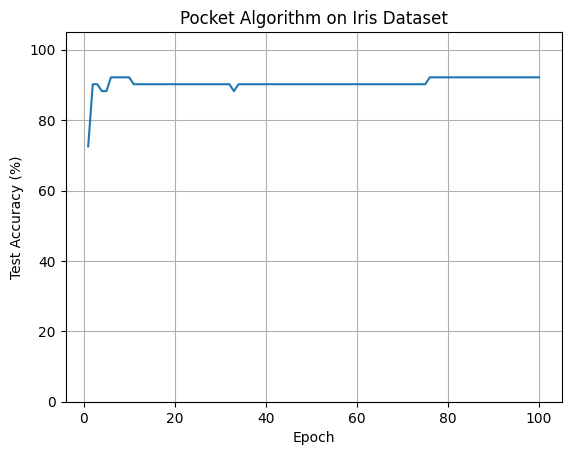

In [1]:
import random
import matplotlib.pyplot as plt



# Read the dataset


file = open("/content/iris data set.csv", "r")

features = []
labels = []

is_header = True
for line in file:
    line = line.strip()

    if line != "":
        # Skip header line
        if is_header:
            is_header = False
            continue

        # Handle both tab and comma-separated formats
        if "\t" in line:
            values = line.split("\t")
        else:
            values = line.split(",")

        row_features = []

        for column in range(4):
            row_features.append(float(values[column]))

        row_label = values[4]

        features.append(row_features)
        labels.append(row_label)

file.close()


# Three output classes
classes = [
    "Iris-setosa",
    "Iris-versicolor",
    "Iris-virginica"
]

number_of_features = 4

print("Total records:", len(features))
print("Number of features:", number_of_features)

for flower_class in classes:
    count = 0

    for label in labels:
        if label == flower_class:
            count += 1

    print(flower_class, ":", count)



# STRATIFIED TRAIN-TEST SPLIT (2:1)


random.seed(42)

train_indices = []
test_indices = []

for flower_class in classes:

    class_indices = []

    for i in range(len(labels)):
        if labels[i] == flower_class:
            class_indices.append(i)

    random.shuffle(class_indices)

    train_count = (len(class_indices) * 2) // 3

    for i in range(len(class_indices)):
        if i < train_count:
            train_indices.append(class_indices[i])
        else:
            test_indices.append(class_indices[i])


random.shuffle(train_indices)
random.shuffle(test_indices)

train_features = []
train_labels = []

test_features = []
test_labels = []

for i in train_indices:
    train_features.append(features[i])
    train_labels.append(labels[i])

for i in test_indices:
    test_features.append(features[i])
    test_labels.append(labels[i])


print("\nTraining records:", len(train_features))
print("Testing records:", len(test_features))



# NORMALIZE THE FEATURES


minimum = []
maximum = []

# Calculate minimum and maximum using training data only.
for column in range(number_of_features):

    smallest = train_features[0][column]
    largest = train_features[0][column]

    for row in range(len(train_features)):

        value = train_features[row][column]

        if value < smallest:
            smallest = value

        if value > largest:
            largest = value

    minimum.append(smallest)
    maximum.append(largest)


# Normalize training data.
normalized_train = []

for row in range(len(train_features)):

    new_row = []

    for column in range(number_of_features):

        difference = maximum[column] - minimum[column]

        if difference != 0:
            normalized_value = (
                (train_features[row][column] - minimum[column])
                / difference
            )
        else:
            normalized_value = 0.0

        new_row.append(normalized_value)

    normalized_train.append(new_row)


# Normalize testing data using training minimum and maximum.
normalized_test = []

for row in range(len(test_features)):

    new_row = []

    for column in range(number_of_features):

        difference = maximum[column] - minimum[column]

        if difference != 0:
            normalized_value = (
                (test_features[row][column] - minimum[column])
                / difference
            )
        else:
            normalized_value = 0.0

        new_row.append(normalized_value)

    normalized_test.append(new_row)



# PREDICTION FUNCTION


def calculate_score(input_values, current_weights, current_bias):

    score = current_bias

    for i in range(number_of_features):
        score += current_weights[i] * input_values[i]

    return score


def predict_binary(input_values, current_weights, current_bias):

    score = calculate_score(
        input_values,
        current_weights,
        current_bias
    )

    if score >= 0:
        return 1
    else:
        return -1



# COUNT CORRECT BINARY PREDICTIONS


def count_correct_binary(
    data,
    actual_labels,
    current_class,
    current_weights,
    current_bias
):

    correct = 0

    for i in range(len(data)):

        if actual_labels[i] == current_class:
            target = 1
        else:
            target = -1

        prediction = predict_binary(
            data[i],
            current_weights,
            current_bias
        )

        if prediction == target:
            correct += 1

    return correct



#  MULTI-CLASS PREDICTION


def predict_multiclass(input_values, models):

    best_class = None
    highest_score = None

    for flower_class in classes:

        current_weights = models[flower_class]["weights"]
        current_bias = models[flower_class]["bias"]

        score = calculate_score(
            input_values,
            current_weights,
            current_bias
        )

        if highest_score is None or score > highest_score:

            highest_score = score
            best_class = flower_class

    return best_class



# COUNT MULTI-CLASS CORRECT PREDICTIONS


def count_correct_multiclass(data, actual_labels, models):

    correct = 0

    for i in range(len(data)):

        prediction = predict_multiclass(data[i], models)

        if prediction == actual_labels[i]:
            correct += 1

    return correct



# INITIALIZE THREE PERCEPTRON MODELS


learning_rate = 0.1
number_of_epochs = 100

models = {}

for flower_class in classes:

    weights = []

    for i in range(number_of_features):
        weights.append(random.uniform(-0.5, 0.5))

    bias = 0.0

    models[flower_class] = {
        "weights": weights,
        "bias": bias,
        "pocket_weights": weights.copy(),
        "pocket_bias": bias,
        "best_correct": 0
    }


# Initialize pocket accuracy for each classifier.
for flower_class in classes:

    model = models[flower_class]

    model["best_correct"] = count_correct_binary(
        normalized_train,
        train_labels,
        flower_class,
        model["pocket_weights"],
        model["pocket_bias"]
    )



# POCKET ALGORITHM TRAINING


accuracy_history = []

for epoch in range(number_of_epochs):

    for flower_class in classes:

        model = models[flower_class]

        # Visit training records in random order.
        row_indices = list(range(len(normalized_train)))
        random.shuffle(row_indices)

        for row in row_indices:

            input_values = normalized_train[row]

            if train_labels[row] == flower_class:
                target = 1
            else:
                target = -1

            predicted_class = predict_binary(
                input_values,
                model["weights"],
                model["bias"]
            )

            # Update weights only when prediction is incorrect.
            if predicted_class != target:

                for i in range(number_of_features):

                    model["weights" ][i] += (
                        learning_rate * target * input_values[i]
                    )

                model["bias"] += learning_rate * target


            # Check current training accuracy.
            current_correct = count_correct_binary(
                normalized_train,
                train_labels,
                flower_class,
                model["weights"],
                model["bias"]
            )

            # Save better weights in the pocket.
            if current_correct > model["best_correct"]:

                model["best_correct"] = current_correct

                model["pocket_weights"] = (
                    model["weights"].copy()
                )

                model["pocket_bias"] = model["bias"]



    # EVALUATE POCKET MODELS AFTER EACH EPOCH


    # Use pocket weights for multi-class prediction.
    pocket_models = {}

    for flower_class in classes:

        pocket_models[flower_class] = {
            "weights": models[flower_class]["pocket_weights"],
            "bias": models[flower_class]["pocket_bias"]
        }


    correct_test = count_correct_multiclass(
        normalized_test,
        test_labels,
        pocket_models
    )

    test_accuracy = (
        correct_test / len(test_labels)
    ) * 100

    accuracy_history.append(test_accuracy)

    correct_train = count_correct_multiclass(
        normalized_train,
        train_labels,
        pocket_models
    )

    training_accuracy = (
        correct_train / len(train_labels)
    ) * 100

    print(
        "Epoch:", epoch + 1,
        "| Training Accuracy:", round(training_accuracy, 2), "%",
        "| Test Accuracy:", round(test_accuracy, 2), "%"
    )



# FINAL RESULTS


final_models = {}

for flower_class in classes:

    final_models[flower_class] = {
        "weights": models[flower_class]["pocket_weights"],
        "bias": models[flower_class]["pocket_bias"]
    }


final_train_correct = count_correct_multiclass(
    normalized_train,
    train_labels,
    final_models
)

final_test_correct = count_correct_multiclass(
    normalized_test,
    test_labels,
    final_models
)

final_train_accuracy = (
    final_train_correct / len(train_labels)
) * 100

final_test_accuracy = (
    final_test_correct / len(test_labels)
) * 100


print("\n========== FINAL POCKET RESULTS ==========")

print("Training records:", len(train_features))
print("Testing records:", len(test_features))

print(
    "Training correct predictions:",
    final_train_correct, "out of", len(train_labels)
)

print(
    "Testing correct predictions:",
    final_test_correct, "out of", len(test_labels)
)

print("Final training accuracy:", round(final_train_accuracy, 2), "%")
print("Final testing accuracy:", round(final_test_accuracy, 2), "%")


# Display final pocket weights.
for flower_class in classes:

    print("\nClass:", flower_class)
    print("Pocket weights:", models[flower_class]["pocket_weights"])
    print("Pocket bias:", models[flower_class]["pocket_bias"])



# EPOCH VS TEST ACCURACY GRAPH


epochs = []

for i in range(number_of_epochs):
    epochs.append(i + 1)

plt.plot(epochs, accuracy_history)

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")

plt.title("Pocket Algorithm on Iris Dataset")

plt.grid(True)
plt.ylim(0, 105)

plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')